Saved: deg_vs_v8_precision.png


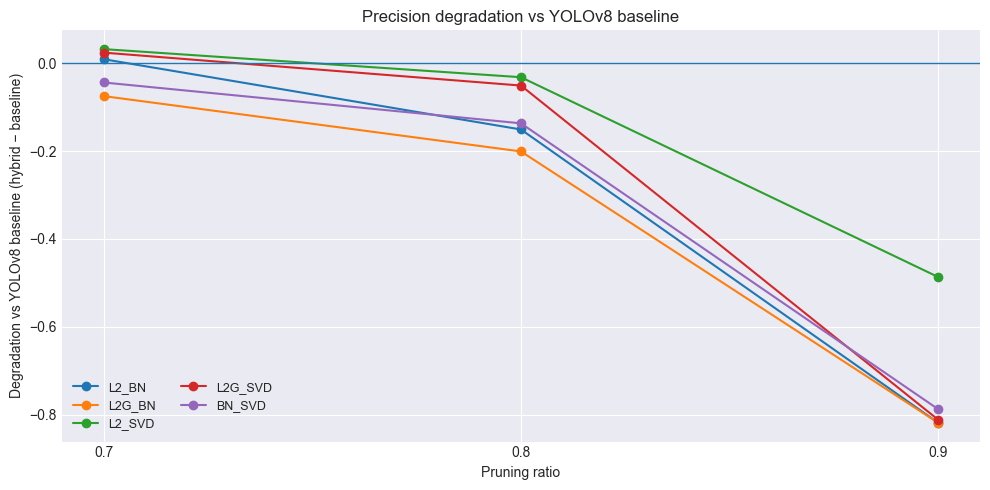

Saved: deg_vs_v8_recall.png


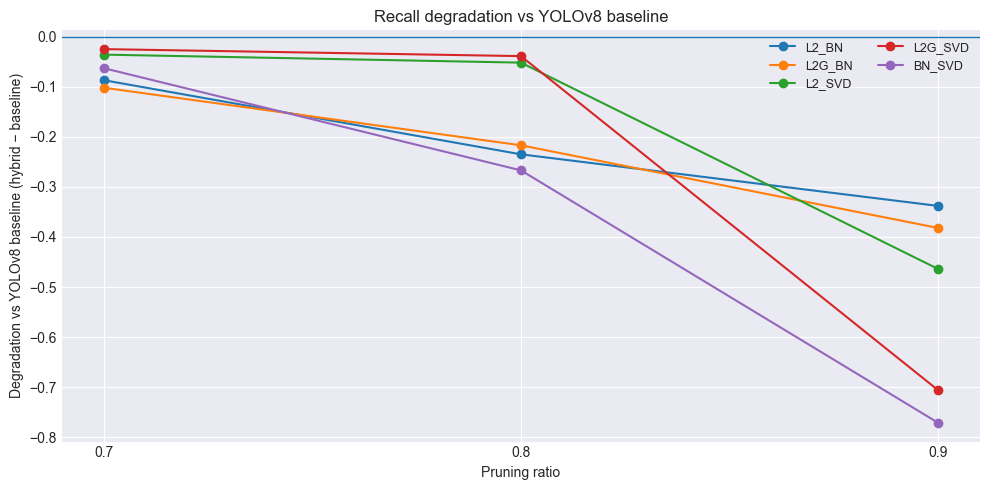

Saved: deg_vs_v8_map50.png


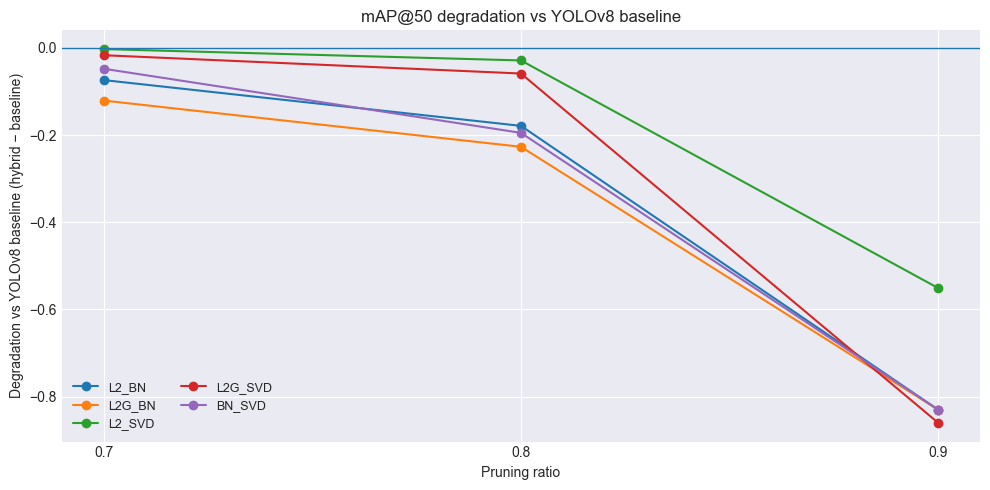

Saved: deg_vs_v8_map50_95.png


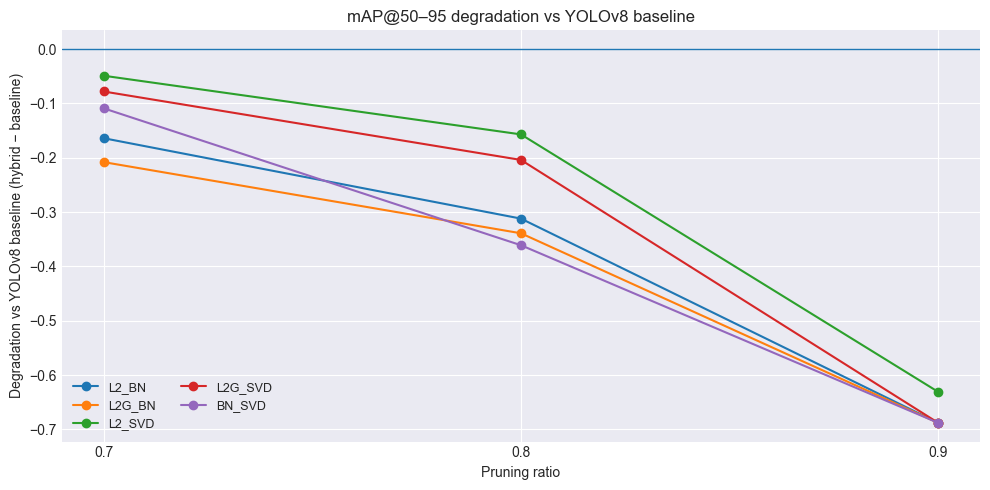

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# =========================================================
# Degradation vs YOLOv8 baseline (unpruned):
#   Δ = (Hybrid pruned metric) - (Baseline YOLOv8 metric)
# Then plots Δ vs pruning ratio for each hybrid method.
# =========================================================

ratios = [0.7, 0.8, 0.9]
methods = ["L2_BN", "L2G_BN", "L2_SVD", "L2G_SVD", "BN_SVD"]

# -----------------------------
# YOLOv8 BASELINE (UNPRUNED)
# (from your table)
# -----------------------------
baseline_v8 = {
    "precision": 0.919,
    "recall": 0.871,
    "map50": 0.930,
    "map50_95": 0.788,
}

# -----------------------------
# HYBRID PRUNING RESULTS (YOLOv8)
# (Before Quant table you sent)
# -----------------------------
hybrid = {
    "precision": {
        0.7: [0.928, 0.844, 0.951, 0.943, 0.875],
        0.8: [0.768, 0.718, 0.887, 0.868, 0.782],
        0.9: [0.100, 0.100, 0.432, 0.107, 0.131],
    },
    "recall": {
        0.7: [0.784, 0.769, 0.835, 0.846, 0.808],
        0.8: [0.636, 0.654, 0.819, 0.832, 0.604],
        0.9: [0.533, 0.489, 0.407, 0.165, 0.100],
    },
    "map50": {
        0.7: [0.856, 0.809, 0.927, 0.913, 0.882],
        0.8: [0.751, 0.703, 0.901, 0.871, 0.735],
        0.9: [0.100, 0.100, 0.379, 0.070, 0.100],
    },
    "map50_95": {
        0.7: [0.624, 0.580, 0.739, 0.710, 0.679],
        0.8: [0.476, 0.449, 0.631, 0.584, 0.427],
        0.9: [0.100, 0.100, 0.157, 0.100, 0.100],
    },
}

# =========================
# Helpers
# =========================
TITLE = {
    "precision": "Precision",
    "recall": "Recall",
    "map50": "mAP@50",
    "map50_95": "mAP@50–95",
}

def to_df(metric_dict):
    df = pd.DataFrame(index=ratios, columns=methods, dtype=float)
    for r in ratios:
        df.loc[r] = metric_dict[r]
    return df

hybrid_df = {k: to_df(v) for k, v in hybrid.items()}

def plot_degradation_vs_baseline(metric_key, save_path=None):
    """
    Δ = hybrid - baseline_v8
    """
    base = baseline_v8[metric_key]
    delta = hybrid_df[metric_key] - base  # subtract scalar

    plt.figure(figsize=(10, 5))
    for m in methods:
        plt.plot(ratios, delta[m].values.astype(float), marker="o", label=m)

    plt.axhline(0.0, linewidth=1)
    plt.xticks(ratios)
    plt.xlabel("Pruning ratio")
    plt.ylabel("Degradation vs YOLOv8 baseline (hybrid − baseline)")
    plt.title(f"{TITLE[metric_key]} degradation vs YOLOv8 baseline")
    plt.legend(ncols=2, fontsize=9)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=200)
        print("Saved:", save_path)

    plt.show()

# =========================
# Run: creates 4 plots
# =========================
for metric in ["precision", "recall", "map50", "map50_95"]:
    plot_degradation_vs_baseline(metric, save_path=f"deg_vs_v8_{metric}.png")
